# Multiple Linear Regression
**IBM Machine Learning with Python Lab**

Estimated time needed: **15 minutes**

---

### Objectives
After completing this lab, you will be able to:
- Understand the concept and mathematical foundation of Multiple Linear Regression ($y = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + \dots + \theta_n x_n$).
- Use `scikit-learn` to implement, train, and test a Multiple Linear Regression model on real vehicle emission data.
- Split data into training and testing sets to evaluate out-of-sample accuracy.
- Evaluate model performance using standard regression metrics: **MAE**, **MSE**, and **R2-Score**.
- Complete all lab exercises (Exercise 1 through Exercise 5) including single-feature isolations and model diagnostics.
- Analyze model fits and understand why non-linear relationships occur with `FUELCONSUMPTION_COMB_MPG` and how to improve them.

---

### Understanding the Data
The dataset `FuelConsumptionCo2.csv` contains vehicle features and carbon dioxide ($CO_2$) emissions:
- **ENGINESIZE**: Engine displacement in liters (e.g., 2.0, 3.5, 4.0)
- **CYLINDERS**: Number of cylinders (e.g., 4, 6, 8)
- **FUELCONSUMPTION_CITY**: City fuel consumption in L/100 km
- **FUELCONSUMPTION_HWY**: Highway fuel consumption in L/100 km
- **FUELCONSUMPTION_COMB**: Combined fuel consumption in L/100 km
- **FUELCONSUMPTION_COMB_MPG**: Combined fuel consumption in Miles Per Gallon (MPG)
- **CO2EMISSIONS**: Tailpipe carbon dioxide emissions in g/km (target variable $y$)


## 1. Importing Needed Packages

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import pylab as pl
import numpy as np
from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
%matplotlib inline

## 2. Downloading and Reading the Data
We load the dataset directly from IBM Cloud Object Storage into a Pandas DataFrame.

In [2]:
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML0101EN-SkillsNetwork/labs/Module%202/data/FuelConsumptionCo2.csv"
df = pd.read_csv(url)

# Display the first 5 rows
df.head()

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2014,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,2014,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,2014,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,2014,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,2014,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


## 3. Data Exploration & Feature Selection
Let's inspect the summary statistics and select features of interest.

In [3]:
df.describe()

,MODELYEAR,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
count,1067.0,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000
mean,2014.0,3.346298,5.794752,13.296532,9.474602,11.580881,26.441425,256.228679
std,0.0,1.415895,1.797447,4.101253,2.794510,3.485595,7.468702,63.372304
min,2014.0,1.000000,3.000000,4.600000,4.900000,4.700000,11.000000,108.000000
25%,2014.0,2.000000,4.000000,10.250000,7.500000,9.000000,21.000000,207.000000
50%,2014.0,3.400000,6.000000,12.600000,8.800000,10.900000,26.000000,251.000000
75%,2014.0,4.300000,8.000000,15.550000,10.850000,13.350000,31.000000,294.000000
max,2014.0,8.400000,12.000000,30.200000,20.500000,25.800000,60.000000,488.000000


### Selecting Features
For this lab, we select `ENGINESIZE`, `FUELCONSUMPTION_COMB_MPG`, and `CO2EMISSIONS`.
Notice that `FUELCONSUMPTION_COMB_MPG` measures fuel economy in Miles Per Gallon (higher is better/more efficient), in contrast to Liters per 100 km (where lower is more efficient).

In [4]:
cdf = df[['ENGINESIZE', 'FUELCONSUMPTION_COMB_MPG', 'CO2EMISSIONS']]
cdf.head(9)

,ENGINESIZE,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2.0,33,196
1,2.4,29,221
2,1.5,48,136
3,3.5,25,255
4,3.5,27,244
5,3.5,28,230
6,3.5,28,232
7,3.7,25,255
8,3.7,24,267


### Visualizing Features vs. CO2 Emissions

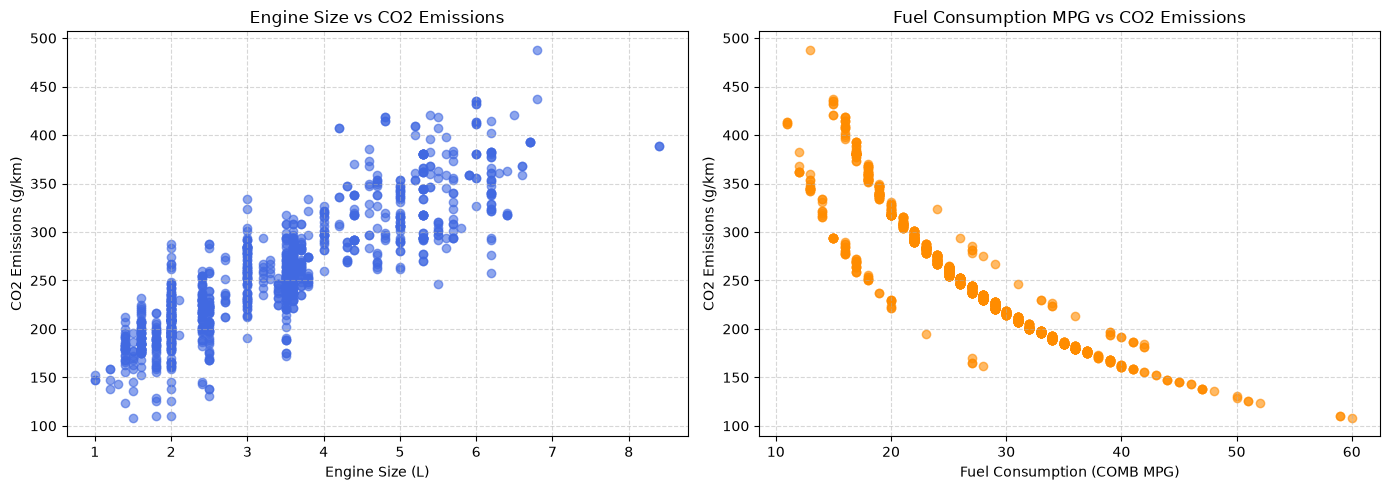

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. ENGINESIZE vs CO2EMISSIONS
axes[0].scatter(cdf.ENGINESIZE, cdf.CO2EMISSIONS, color='royalblue', alpha=0.6)
axes[0].set_xlabel("Engine Size (L)")
axes[0].set_ylabel("CO2 Emissions (g/km)")
axes[0].set_title("Engine Size vs CO2 Emissions")
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. FUELCONSUMPTION_COMB_MPG vs CO2EMISSIONS
axes[1].scatter(cdf.FUELCONSUMPTION_COMB_MPG, cdf.CO2EMISSIONS, color='darkorange', alpha=0.6)
axes[1].set_xlabel("Fuel Consumption (COMB MPG)")
axes[1].set_ylabel("CO2 Emissions (g/km)")
axes[1].set_title("Fuel Consumption MPG vs CO2 Emissions")
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## 4. Creating Train and Test Datasets

We split the feature matrix $X$ and target vector $y$ into:
- **Training Set (80%)**: Used to fit the regression model.
- **Testing Set (20%)**: Kept unseen during training to evaluate generalizability on new data.

Here:
- Column 0 of $X$ is `ENGINESIZE`.
- Column 1 of $X$ is `FUELCONSUMPTION_COMB_MPG`.

In [6]:
X = cdf[['ENGINESIZE', 'FUELCONSUMPTION_COMB_MPG']].to_numpy()
y = cdf[['CO2EMISSIONS']].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Total samples:     {len(df)}")
print(f"X_train shape:     {X_train.shape}")
print(f"X_test shape:      {X_test.shape}")
print(f"Feature at col 0:  ENGINESIZE")
print(f"Feature at col 1:  FUELCONSUMPTION_COMB_MPG")

Total samples:     1067
X_train shape:     (853, 2)
X_test shape:      (214, 2)
Feature at col 0:  ENGINESIZE
Feature at col 1:  FUELCONSUMPTION_COMB_MPG


## 5. Multiple Linear Regression Model

When more than one independent variable is present, the process is called Multiple Linear Regression.
The model equation is:
$$\hat{y} = \theta_0 + \theta_1 x_1 + \theta_2 x_2$$

Where:
- $\hat{y}$ = Predicted `CO2EMISSIONS`
- $x_1$ = `ENGINESIZE`
- $x_2$ = `FUELCONSUMPTION_COMB_MPG`
- $\theta_0$ = Intercept
- $\theta_1, \theta_2$ = Regression coefficients (slopes)

The Ordinary Least Squares (OLS) algorithm determines the parameters that minimize the sum of squared residuals across all training examples.

In [7]:
# Instantiate and train the Multiple Linear Regression model
multiple_regr = linear_model.LinearRegression()
multiple_regr.fit(X_train, y_train)

print("Coefficients (θ1, θ2):", multiple_regr.coef_)
print("Intercept (θ0):       ", multiple_regr.intercept_)
print(f"\nFitted Equation: CO2 = {multiple_regr.intercept_[0]:.2f} + ({multiple_regr.coef_[0][0]:.2f} * ENGINESIZE) + ({multiple_regr.coef_[0][1]:.2f} * FUELCONSUMPTION_COMB_MPG)")

Coefficients (θ1, θ2): [[17.8581369  -5.01502179]]
Intercept (θ0):        [329.1363967]

Fitted Equation: CO2 = 329.14 + (17.86 * ENGINESIZE) + (-5.02 * FUELCONSUMPTION_COMB_MPG)


### Evaluating Multiple Linear Regression on Test Data

In [8]:
y_hat_mult = multiple_regr.predict(X_test)

mae_mult = mean_absolute_error(y_test, y_hat_mult)
mse_mult = mean_squared_error(y_test, y_hat_mult)
r2_mult = r2_score(y_test, y_hat_mult)

print("--- Multiple Linear Regression Results ---")
print("Mean Absolute Error (MAE): %.2f" % mae_mult)
print("Residual sum of squares (MSE): %.2f" % mse_mult)
print("R2-score:                 %.4f" % r2_mult)

--- Multiple Linear Regression Results ---
Mean Absolute Error (MAE): 14.29
Residual sum of squares (MSE): 466.11
R2-score:                 0.8873


---
## 6. Single Feature Modeling: Exercises 1, 2, and 3 (`ENGINESIZE`)

Now we isolate single features from our dataset to compare their individual predictive behavior against the multiple regression model.

### Exercise 1: Fit a Simple Linear Model using `ENGINESIZE` (Column 0)

In [9]:
# Exercise 1: Extract feature column 0 (ENGINESIZE) and train simple regression
X_train_1 = X_train[:, 0].reshape(-1, 1)
X_test_1 = X_test[:, 0].reshape(-1, 1)

regressor_1 = linear_model.LinearRegression()
regressor_1.fit(X_train_1, y_train)

print("Coefficient (θ1):", regressor_1.coef_)
print("Intercept (θ0):  ", regressor_1.intercept_)

Coefficient (θ1): [[38.99297872]]
Intercept (θ0):   [126.28970217]


### Exercise 2: Plot Regression Line on Training Data

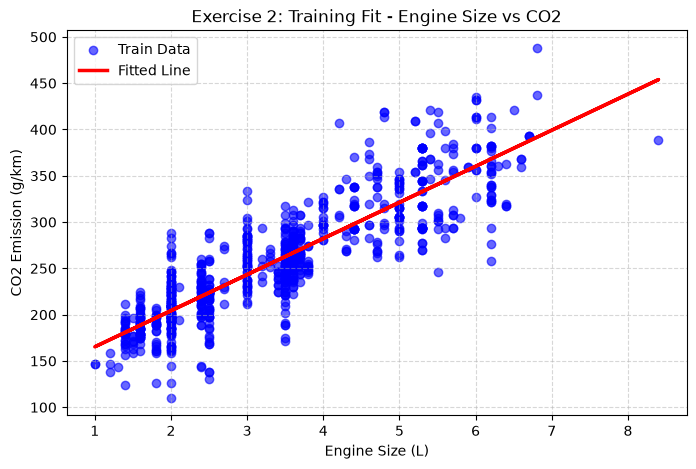

In [10]:
# Exercise 2: Plot training set and regression line
plt.figure(figsize=(8, 5))
plt.scatter(X_train_1, y_train, color='blue', alpha=0.6, label='Train Data')
plt.plot(X_train_1, regressor_1.coef_[0] * X_train_1 + regressor_1.intercept_, '-r', linewidth=2.5, label='Fitted Line')
plt.xlabel("Engine Size (L)")
plt.ylabel("CO2 Emission (g/km)")
plt.title("Exercise 2: Training Fit - Engine Size vs CO2")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Exercise 3: Plot Regression Line on Testing Data

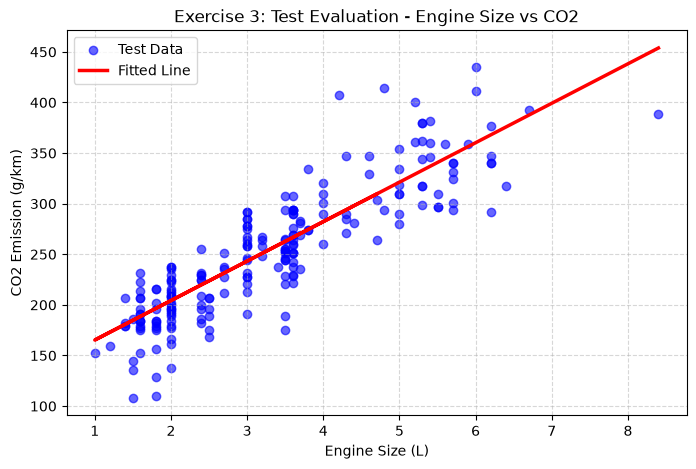

Model 1 (ENGINESIZE) Test MSE: 985.94
Model 1 (ENGINESIZE) Test R2:  0.7616


In [11]:
# Exercise 3: Plot test set and regression line
plt.figure(figsize=(8, 5))
plt.scatter(X_test_1, y_test, color='blue', alpha=0.6, label='Test Data')
plt.plot(X_test_1, regressor_1.coef_[0] * X_test_1 + regressor_1.intercept_, '-r', linewidth=2.5, label='Fitted Line')
plt.xlabel("Engine Size (L)")
plt.ylabel("CO2 Emission (g/km)")
plt.title("Exercise 3: Test Evaluation - Engine Size vs CO2")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

mse_model1 = mean_squared_error(y_test, regressor_1.predict(X_test_1))
r2_model1 = r2_score(y_test, regressor_1.predict(X_test_1))
print("Model 1 (ENGINESIZE) Test MSE: %.2f" % mse_model1)
print("Model 1 (ENGINESIZE) Test R2:  %.4f" % r2_model1)

---
## 7. Exercise 4: Modeling with `FUELCONSUMPTION_COMB_MPG`

**Prompt**:
> Repeat the same modeling but use FUELCONSUMPTION_COMB_MPG as the independent variable instead. Display the model coefficients including the intercept.
>
> `X_train_2 = # ADD CODE`

**Solution**:
We extract column index 1 from `X_train` (which corresponds to `FUELCONSUMPTION_COMB_MPG`) and reshape it into a 2D array of shape `(N, 1)`. Then we fit `linear_model.LinearRegression()`.

In [12]:
# Exercise 4: Fit regression using FUELCONSUMPTION_COMB_MPG (Column 1)
X_train_2 = X_train[:, 1].reshape(-1, 1)

regressor_2 = linear_model.LinearRegression()
regressor_2.fit(X_train_2, y_train)

# Display the model coefficients including the intercept
coef_2 = regressor_2.coef_
intercept_2 = regressor_2.intercept_

print("Coefficients:", coef_2)
print("Intercept:   ", intercept_2)
print(f"\nFitted Equation: CO2 = {intercept_2[0]:.2f} + ({coef_2[0][0]:.2f} * FUELCONSUMPTION_COMB_MPG)")

Coefficients: [[-7.83880802]]
Intercept:    [463.36317263]

Fitted Equation: CO2 = 463.36 + (-7.84 * FUELCONSUMPTION_COMB_MPG)


---
## 8. Exercise 5: Plotting Test Results and Evaluating Model Fits

**Prompt**:
> Generate a scatter plot showing the results as before on the test data. Consider well the model fits, and what you might be able to do to improve it. We'll revisit this later in the course.
>
> `# write your code here`
> `X_test_2 = X_test[:,# ADD CODE]`
> `plt.scatter(X_test_2, # ADD CODE,  color='blue')`
> `plt.plot(X_test_2, # ADD CODE, '-r')`
> `plt.xlabel("# ADD CODE")`
> `plt.ylabel("CO2 Emission")`

**Solution**:
We extract `X_test[:, 1]`, plot the test points against `y_test`, and draw the linear prediction line.

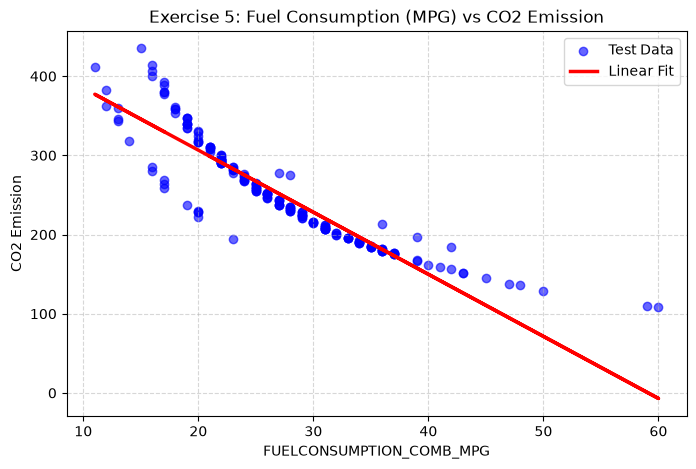

Model 2 (MPG) Test MSE: 776.21
Model 2 (MPG) Test R2:  0.8123


In [13]:
# Exercise 5: Generate scatter plot on test data with the fitted line
X_test_2 = X_test[:, 1]

plt.figure(figsize=(8, 5))
plt.scatter(X_test_2, y_test, color='blue', alpha=0.6, label='Test Data')
plt.plot(X_test_2, coef_2[0][0] * X_test_2 + intercept_2[0], '-r', linewidth=2.5, label='Linear Fit')
plt.xlabel("FUELCONSUMPTION_COMB_MPG")
plt.ylabel("CO2 Emission")
plt.title("Exercise 5: Fuel Consumption (MPG) vs CO2 Emission")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

X_test_2_2d = X_test[:, 1].reshape(-1, 1)
mse_model2 = mean_squared_error(y_test, regressor_2.predict(X_test_2_2d))
r2_model2 = r2_score(y_test, regressor_2.predict(X_test_2_2d))
print("Model 2 (MPG) Test MSE: %.2f" % mse_model2)
print("Model 2 (MPG) Test R2:  %.4f" % r2_model2)

## 9. Comprehensive Comparison of All Three Models

Let's summarize the evaluation metrics on the test data across all three models:

In [14]:
summary_df = pd.DataFrame({
    'Model': [
        '1. Simple Linear Regression (ENGINESIZE)',
        '2. Simple Linear Regression (FUELCONSUMPTION_COMB_MPG)',
        '3. Multiple Linear Regression (Both Features)'
    ],
    'Independent Variables': [
        'ENGINESIZE',
        'FUELCONSUMPTION_COMB_MPG',
        'ENGINESIZE + FUELCONSUMPTION_COMB_MPG'
    ],
    'MSE (Lower is better)': [mse_model1, mse_model2, mse_mult],
    'R2-Score (Higher is better)': [r2_model1, r2_model2, r2_mult]
})

summary_df.round(2)

,Model,Independent Variables,MSE (Lower is better),R2-Score (Higher is better)
0,1. Simple Linear Regression (ENGINESIZE),ENGINESIZE,985.94,0.76
1,2. Simple Linear Regression (FUELCONSUMPTION_C...,FUELCONSUMPTION_COMB_MPG,776.21,0.81
2,3. Multiple Linear Regression (Both Features),ENGINESIZE + FUELCONSUMPTION_COMB_MPG,466.11,0.89


### In-Depth Analysis: Addressing Exercise 5 Reflection

> *"Consider well the model fits, and what you might be able to do to improve it. We'll revisit this later in the course."*

#### 1. Why does `FUELCONSUMPTION_COMB_MPG` have a negative slope?
- `FUELCONSUMPTION_COMB_MPG` measures fuel economy in **Miles Per Gallon**.
- Higher MPG means the car travels more distance per gallon of fuel burned (it is more fuel-efficient).
- Therefore, as MPG increases, the quantity of fuel burned per kilometer decreases, leading to lower carbon dioxide emissions.
- This creates an inverse (negative) relationship ($	heta_1 = -7.84$).

#### 2. Why is a straight line not an optimal fit for MPG?
- Physical reality: Fuel burned per distance is proportional to $\frac{1}{\text{MPG}}$.
  $$\text{L/100 km} \approx \frac{282.48}{\text{MPG}}$$
- Because $CO_2$ emission is strictly proportional to the volume of fuel combusted:
  $$\text{CO2} \propto \frac{1}{\text{MPG}}$$
- The relationship between $CO_2$ emissions and MPG is mathematically **hyperbolic (reciprocal / non-linear)**, forming a distinct downward curve rather than a flat straight line.
- A linear model systematically overpredicts in the middle of the MPG range and underpredicts at the extreme ends.

#### 3. What can be done to improve the model?
As revisited later in the course:
1. **Polynomial Regression**: Include higher-order powers of the feature (e.g., $x^2, x^3$) to allow the regression curve to bend with the true data distribution:
   $$\hat{y} = \theta_0 + \theta_1 x + \theta_2 x^2$$
2. **Feature Transformation**: Transform the feature using the reciprocal $x' = \frac{1}{\text{MPG}}$ (or using `FUELCONSUMPTION_COMB` in L/100km). This linearizes the underlying physical relationship.
3. **Multiple Linear Regression**: As demonstrated in Section 5, combining multiple features (`ENGINESIZE` + `FUELCONSUMPTION_COMB_MPG`) significantly improves accuracy, reducing the MSE from **985.94** (Engine size alone) and **776.21** (MPG alone) down to **466.11**, while driving the $R^2$ score up to **0.8873**.
